# 05 - Artifact templates and injection (milestone 6)

`PROJECT_PLAN.md` §9.3 step 6. Phantom templates (primary): the brain
component, predicted from the broadcast brain sources, is regressed out of
each artifact recording; the remainder is spline-mapped to BioSemi 64,
average-referenced and resampled to 128 Hz. PhysioMotion templates
(secondary, ablation): single-class annotated events with the plan's
isolation filters. Then injection into a Dataset III recording at a target
SAR, with the injection log. Also the within-recording phantom transfer
test, which uses window labels from the broadcast artifact sources.

Banks come from `scripts/10_build_templates.py` (cached under
`data/cache/templates/`); set `BUILD = True` to rebuild the phantom Set A
bank here (a few minutes).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adr.config import load_paths, package_versions, seed_everything

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
pd.set_option("display.max_columns", 50, "display.width", 200)
paths = load_paths()
seed_everything()
package_versions()

{'python': '3.14.8',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'pandas': '3.0.6',
 'mne': '1.13.2',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.2',
 'eelbrain': '0.43.0b0',
 'matplotlib': '3.11.2',
 'mne-icalabel': '0.10.0'}

In [2]:
from adr.io import phantom
from adr.synth import dataset3 as d3
from adr.synth import inject as I
from adr.synth import templates as T

BUILD = False
if BUILD:
    phantom_a, stats = T.phantom_templates("set_a_templates")
    print(stats)
else:
    phantom_a = T.load_bank("phantom_set_a_templates")
pm_a = T.load_bank("physiomotion_set_a_templates")
pd.DataFrame({"phantom Set A": pd.Series([t.kind for t in phantom_a]).value_counts(),
              "PhysioMotion Set A": pd.Series([t.kind for t in pm_a]).value_counts()})

,phantom Set A,PhysioMotion Set A
motion,60,200
muscle,60,200
ocular,60,62


## Phantom artifact sources and window labels

The broadcast source waveforms (one ground-truth file for every condition)
and the window labels derived from them. Blinks are about once per second;
saccades and facial (chewing) bursts are intermittent; neck EMG and the
walking platform run continuously.

blink      0.97
saccade    0.43
facial     0.57
dtype: float64

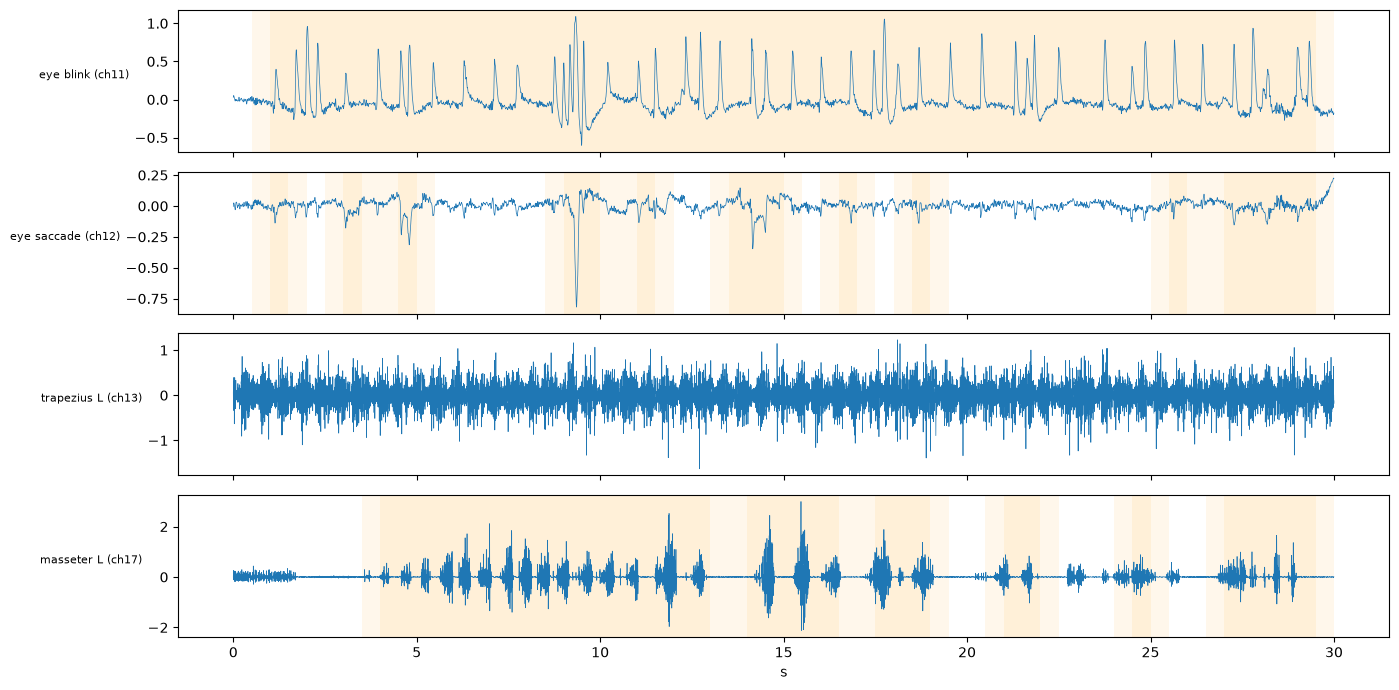

In [3]:
gt = phantom.load_ground_truth()
t = np.arange(512 * 30) / 512
fig, ax = plt.subplots(4, 1, figsize=(14, 7), sharex=True)
for a, (i, name) in zip(ax, [(10, "eye blink (ch11)"), (11, "eye saccade (ch12)"), (12, "trapezius L (ch13)"), (16, "masseter L (ch17)")]):
    a.plot(t, gt[: len(t), i], lw=0.5); a.set_ylabel(name, rotation=0, ha="right", fontsize=8)
act = phantom.source_activity(gt[: len(t)], 512, 1.0, 0.5)
for a, col in zip((ax[0], ax[1], ax[3]), ("blink", "saccade", "facial")):
    for s0 in act.loc[act[col], "start"]:
        a.axvspan(s0, s0 + 1.0, color="orange", alpha=0.08, lw=0)
ax[-1].set_xlabel("s"); fig.tight_layout()
phantom.source_activity(gt, 512, 1.0, 0.5)[["blink", "saccade", "facial"]].mean().round(2)

## What a template looks like

One template per class from each source (BioSemi 64, 128 Hz, µV). Phantom
templates carry the phantom's ~7 µV sensor-noise floor; the facial field is
well above it, the walking (motion) field barely.

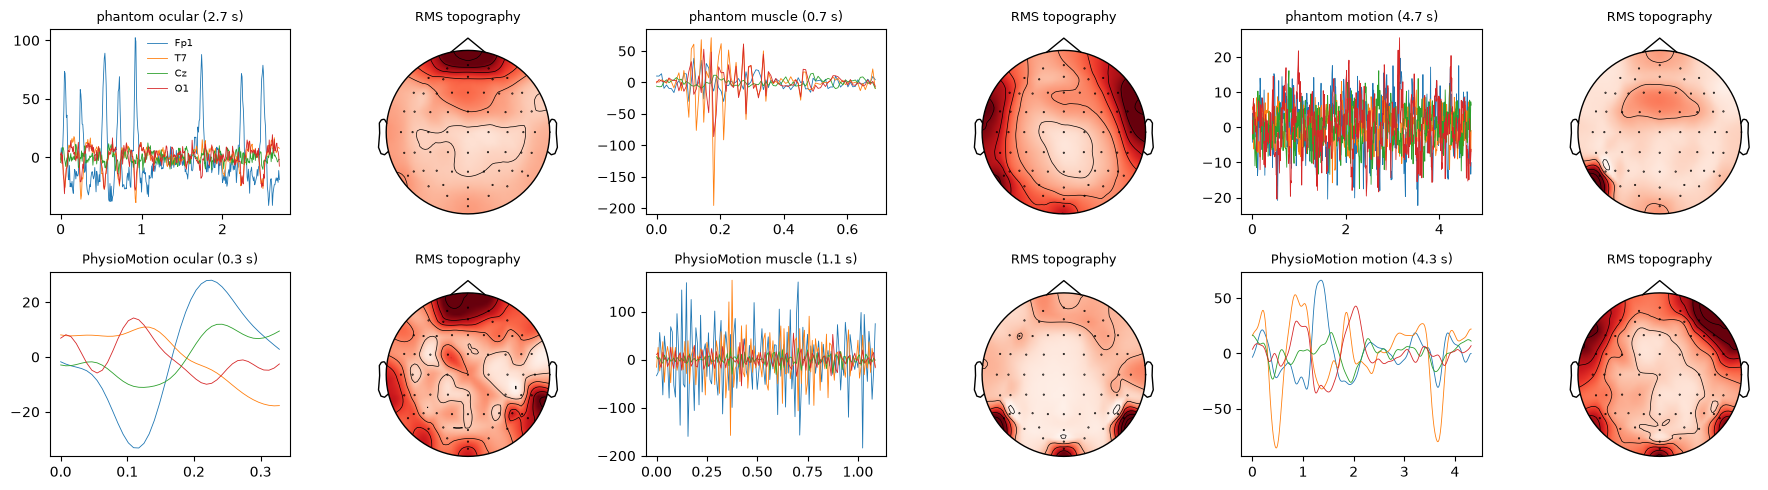

In [4]:
import mne
names, _ = __import__("adr.preprocessing.spline", fromlist=["x"]).biosemi64_positions()
info = mne.create_info(names, 128.0, "eeg"); info.set_montage("biosemi64")
fig, axes = plt.subplots(2, 6, figsize=(18, 5))
rng = np.random.default_rng(0)
for row, (label, bank) in enumerate((("phantom", phantom_a), ("PhysioMotion", pm_a))):
    for k, kind in enumerate(T.CLASSES):
        tpl = [x for x in bank if x.kind == kind][int(rng.integers(0, 10))]
        tt = np.arange(len(tpl.data)) / tpl.fs
        axes[row, 2 * k].plot(tt, tpl.data[:, [names.index(c) for c in ("Fp1", "T7", "Cz", "O1")]] * 1e6, lw=0.6)
        axes[row, 2 * k].set_title(f"{label} {kind} ({tpl.duration:.1f} s)", fontsize=9)
        mne.viz.plot_topomap(np.sqrt((tpl.data ** 2).mean(0)), info, axes=axes[row, 2 * k + 1], show=False)
        axes[row, 2 * k + 1].set_title("RMS topography", fontsize=9)
axes[0, 0].legend(["Fp1", "T7", "Cz", "O1"], fontsize=7, frameon=False)
fig.tight_layout()

## Injection into a Dataset III recording

Set A noise subject, -10 dB SNR, one artifact type at a time, SAR 0 dB.
The injection log is the ground truth for detection scoring.

In [5]:
base, lags, ch64 = d3.load_base_trfs()
split = d3.load_noise_split()
source = d3.noise_source(split["set_a"][0])
rec = d3.synthesize(source, "L", -10, base, lags)
rng = np.random.default_rng(1)
injected = {kind: I.inject(rec.eeg, 128.0, kind, 0.0, rng, bank=phantom_a, ch_names=list(rec.ch_names))
            for kind in I.TYPES}
injected["muscle"].log.head()

,type,onset_s,offset_s,channels,sar_db,gain,source
0,muscle,1.351562,3.781250,all,0.0,1.137497,phantom:Neck
1,muscle,8.984375,10.906250,all,0.0,1.427980,phantom:Neck
2,muscle,14.171875,17.109375,all,0.0,0.548628,phantom:Facial
3,muscle,21.632812,22.929688,all,0.0,1.160469,phantom:Neck
4,muscle,30.898438,32.710938,all,0.0,2.423277,phantom:Neck


,events,per min,time covered
ocular,113.0,2.94,0.10
muscle,128.0,3.33,0.10
motion,116.0,3.02,0.21
pop,127.0,3.31,0.08


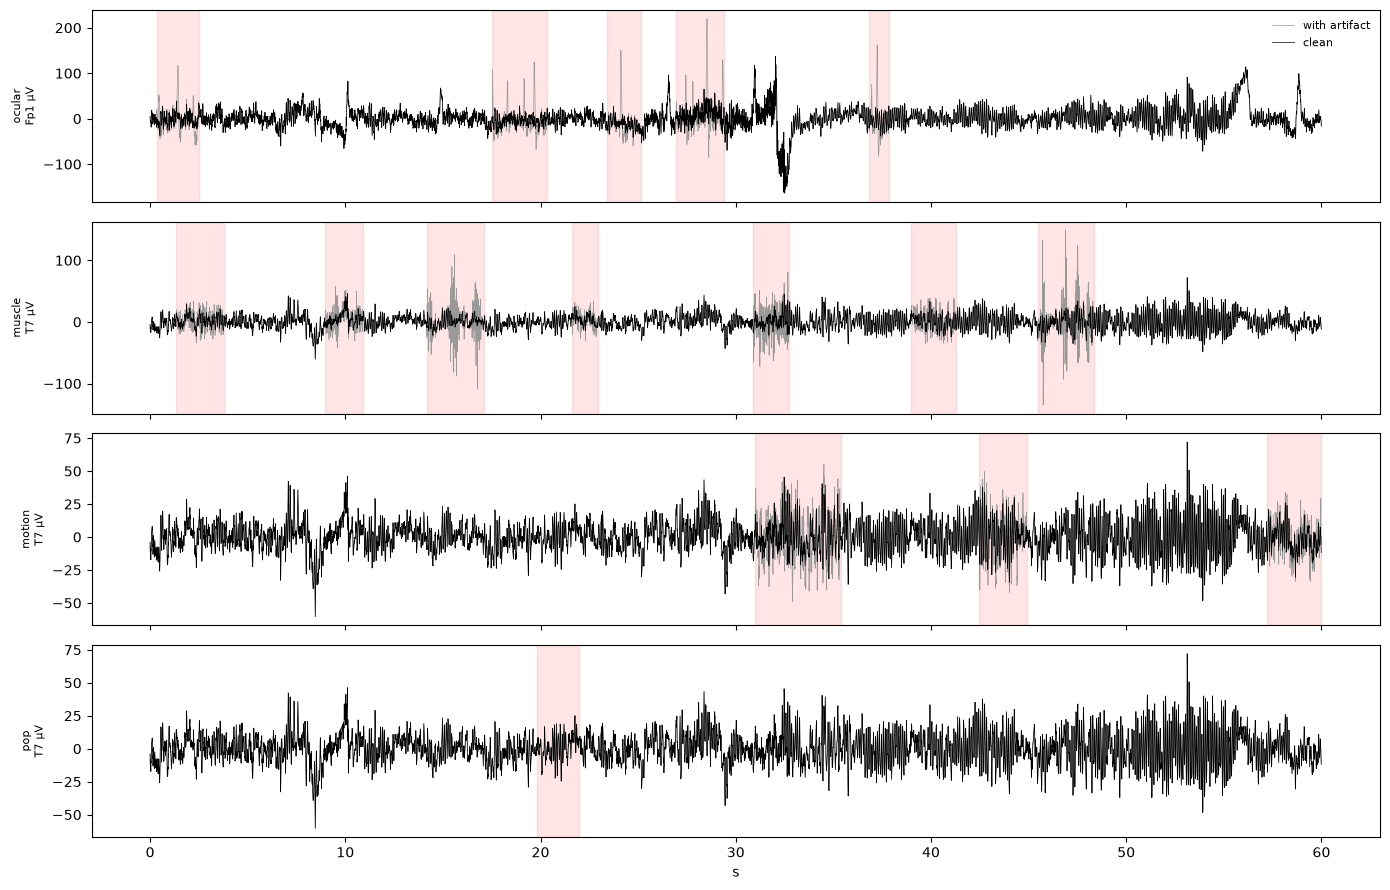

In [6]:
fig, ax = plt.subplots(len(I.TYPES), 1, figsize=(14, 9), sharex=True)
seg = slice(0, 128 * 60)
tt = np.arange(128 * 60) / 128
for a, kind in zip(ax, I.TYPES):
    out = injected[kind]
    ch = list(rec.ch_names).index("Fp1" if kind == "ocular" else "T7")
    a.plot(tt, out.eeg[seg, ch] * 1e6, color="0.6", lw=0.5, label="with artifact")
    a.plot(tt, rec.eeg[seg, ch] * 1e6, color="k", lw=0.5, label="clean")
    for r in out.log.itertuples():
        if r.onset_s < 60:
            a.axvspan(r.onset_s, min(r.offset_s, 60), color="red", alpha=0.1)
    a.set_ylabel(f"{kind}\n{rec.ch_names[ch]} µV", fontsize=8)
ax[0].legend(frameon=False, fontsize=8); ax[-1].set_xlabel("s"); fig.tight_layout()
pd.DataFrame({k: {"events": len(v.log), "per min": len(v.log) / (len(rec.eeg) / 128 / 60),
                  "time covered": float((v.artifact != 0).any(1).mean())} for k, v in injected.items()}).T.round(2)

## Within-recording phantom transfer

AUC of each detector for source-on vs source-off windows inside one phantom
recording (held-out 200-300 s pool). Valid for both detector variants.

In [7]:
RUN_WITHIN = False
from adr.detection import transfer
w = transfer.within_recording() if RUN_WITHIN else pd.read_csv(paths["results"] / "detectors" / "phantom_within_recording.csv")
w.pivot_table(index=["condition", "target", "source"], columns=["rate", "variant", "model"], values="auc_within").round(2)

rate                       128                           250                        
variant                   norm            raw           norm            raw         
model                      lda lightgbm   lda lightgbm   lda lightgbm   lda lightgbm
condition target source                                                             
All       muscle facial   0.83     0.94  0.94     0.98  0.76     0.93  0.85     0.98
          ocular saccade  0.45     0.56  0.56     0.79  0.45     0.49  0.53     0.80
Eyes      ocular blink    0.99     0.74  0.98     0.82  0.99     0.73  0.99     1.00
                 saccade  0.65     0.62  0.60     0.63  0.66     0.63  0.61     0.58
Facial    muscle facial   0.88     0.98  0.95     0.98  0.85     0.96  0.84     0.99